<!-- Run from the repository root; see README.md for Jupyter and Colab setup. -->

# Foreign Direct Investment and Business Investment in Canada, 1981–2018

Replication notebook for *Foreign Direct Investment and Business Investment in Canada* (Porokmi Sambahamphe, 2026).

Run top to bottom. Sections follow the paper:

1. Setup
2. Data: download, capacity gap (HP filter), save
3. Figure 1: the data
4. Unit-root tests (Table 1)
5. Levels models: OLS and AR(1)
6. Cointegration and the error-correction model (Table 2)
7. Residual diagnostics
8. Robustness: currency, sample, interaction (Table 3)
9. Figure 2: FDI coefficient across specifications
10. Export tables

## 1. Setup

In [1]:
# Set REBUILD_DATA = True to download fresh data from Statistics Canada and the World Bank.
# With False, the notebook uses the saved CSV files in data/ (reproduces the paper exactly).
REBUILD_DATA = False

import os, io, zipfile
from pathlib import Path

if not Path("data/fdi_data_1981_2018.csv").exists() and not REBUILD_DATA:
    raise FileNotFoundError(
        "Open this notebook from the cloned repository root, with data/ present. "
        "See README.md for Jupyter and Colab setup. "
        "Set REBUILD_DATA=True only if you intend to download current source data."
    )
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.regression.linear_model import GLSAR
from statsmodels.tsa.filters.hp_filter import hpfilter
from statsmodels.tsa.stattools import adfuller, coint
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import acorr_breusch_godfrey
from statsmodels.iolib.summary2 import summary_col

DATA_DIR, FIG_DIR, TAB_DIR = "data", "figures", "tables"
for folder in (DATA_DIR, FIG_DIR, TAB_DIR):
    os.makedirs(folder, exist_ok=True)

HAC = dict(cov_type="HAC", cov_kwds={"maxlags": 3})   # Newey-West, 3 lags

## 2. Data

* **Business investment (I)**, nominal and real GDP: Statistics Canada Table 36-10-0222-01 (CAD millions).
* **Gross national expenditure (Y)**, **FDI net inflows**, **exchange rate** (CAD per USD): World Bank WDI.
* **Capacity slack (U)**: potential output from an HP filter (λ = 100) on log real GDP over the full available series;
  U = potential − actual, valued at nominal GDP. Positive U means output is below potential.

Two samples are saved: 1981–2018 (main) and 1981–2024 (extension). All money values are in billions.

In [3]:
def build_dataset(start, end, statcan_table):
    t = statcan_table

    def statcan_series(prices, label):
        s = t[(t["GEO"] == "Canada") & (t["Prices"] == prices) &
              (t["Estimates"] == label) & (t["UOM"] == "Dollars")].copy()
        s["year"] = s["REF_DATE"].astype(int)
        s = s.set_index("year")["VALUE"]                     # CAD millions
        assert s.index.is_unique, f"duplicate years for {label}"
        return s

    gdp_label = "Gross domestic product at market prices"
    real_gdp = statcan_series("Chained (2017) dollars", gdp_label)
    nom_gdp  = statcan_series("Current prices", gdp_label)
    bgfcf    = statcan_series("Current prices", "Business gross fixed capital formation")

    # Potential output: HP filter on log real GDP, using all available years
    cycle, trend = hpfilter(np.log(real_gdp.dropna()), lamb=100)
    gap = np.exp(cycle) - 1                                  # actual / potential - 1
    U_cad_mil = nom_gdp / (1 + gap) - nom_gdp                # potential - actual

    codes = {"NE.DAB.TOTL.CD": "Y_usd", "BX.KLT.DINV.CD.WD": "FDI_usd", "PA.NUS.FCRF": "fx"}
    w = wb.data.DataFrame(list(codes), "CAN", time=range(start, end + 1),
                          columns="series", numericTimeKeys=True).rename(columns=codes)

    df = pd.DataFrame(index=w.index)
    df.index.name = "year"
    df["fx"] = w["fx"]
    df["gap_pct"] = (100 * gap).reindex(df.index)
    # US$ billions
    df["I_usd"]   = bgfcf.reindex(df.index) / df["fx"] / 1000
    df["U_usd"]   = U_cad_mil.reindex(df.index) / df["fx"] / 1000
    df["Y_usd"]   = w["Y_usd"] / 1e9
    df["FDI_usd"] = w["FDI_usd"] / 1e9
    # CAD billions
    df["I_cad"]   = bgfcf.reindex(df.index) / 1000
    df["U_cad"]   = U_cad_mil.reindex(df.index) / 1000
    df["Y_cad"]   = df["Y_usd"] * df["fx"]
    df["FDI_cad"] = df["FDI_usd"] * df["fx"]
    return df

# Archived-data mode must not silently download a different data vintage.
missing_files = not (os.path.exists(f"{DATA_DIR}/fdi_data_1981_2018.csv") and
                     os.path.exists(f"{DATA_DIR}/fdi_data_1981_2024.csv"))

if missing_files and not REBUILD_DATA:
    raise FileNotFoundError("Both archived CSVs are required in data/. See README.md.")

if REBUILD_DATA:
    import requests, wbgapi as wb
    url = "https://www150.statcan.gc.ca/n1/tbl/csv/36100222-eng.zip"
    z = zipfile.ZipFile(io.BytesIO(requests.get(url, timeout=120).content))
    statcan = pd.read_csv(z.open("36100222.csv"), low_memory=False)
    for start, end in [(1981, 2018), (1981, 2024)]:
        build_dataset(start, end, statcan).to_csv(f"{DATA_DIR}/fdi_data_{start}_{end}.csv")

base = pd.read_csv(f"{DATA_DIR}/fdi_data_1981_2018.csv", index_col="year")
ext  = pd.read_csv(f"{DATA_DIR}/fdi_data_1981_2024.csv", index_col="year")
print("Main sample:", base.shape, "| Extended sample:", ext.shape)
print("Missing values (main):", int(base.isna().sum().sum()))
base.round(2)

Main sample: (38, 10) | Extended sample: (44, 10)
Missing values (main): 0


,fx,gap_pct,I_usd,U_usd,Y_usd,FDI_usd,I_cad,U_cad,Y_cad,FDI_cad
year,,,,,,,,,,
1981,1.20,2.65,65.00,-7.94,305.51,0.66,77.93,-9.52,366.27,0.80
1982,1.23,-3.27,58.24,10.62,303.65,0.09,71.85,13.10,374.62,0.11
1983,1.23,-3.47,58.68,12.30,331.98,4.62,72.32,15.16,409.14,5.69
1984,1.30,-0.57,58.22,2.04,345.07,5.68,75.40,2.64,446.89,7.35
1985,1.37,1.33,61.26,-4.79,357.79,1.26,83.65,-6.54,488.57,1.72
1986,1.39,0.75,65.47,-2.81,376.16,2.71,90.98,-3.91,522.66,3.77
1987,1.33,2.20,79.32,-9.30,427.41,8.60,105.18,-12.34,566.74,11.40
1988,1.23,4.14,97.20,-20.25,504.77,7.20,119.63,-24.92,621.23,8.86
1989,1.18,4.16,109.68,-22.65,566.29,7.17,129.85,-26.82,670.47,8.49


### Analysis variables

`prep()` creates clean names used throughout: **I, Y, U, FDI** in the chosen currency, first differences **dI, dY**,
the lagged error-correction term **ECT** (residual from the I–Y long-run regression), and a 2020 indicator.

In [4]:
def prep(data, unit="usd"):
    d = data.copy()
    d["I"], d["Y"] = d[f"I_{unit}"], d[f"Y_{unit}"]
    d["U"], d["FDI"] = d[f"U_{unit}"], d[f"FDI_{unit}"]
    d["dI"], d["dY"] = d["I"].diff(), d["Y"].diff()
    d["ECT"] = smf.ols("I ~ Y", data=d).fit().resid.shift(1)
    d["covid"] = (d.index == 2020).astype(int)
    return d

usd, cad, usd_ext = prep(base, "usd"), prep(base, "cad"), prep(ext, "usd")

## 3. Figure 1: investment, FDI and the output gap

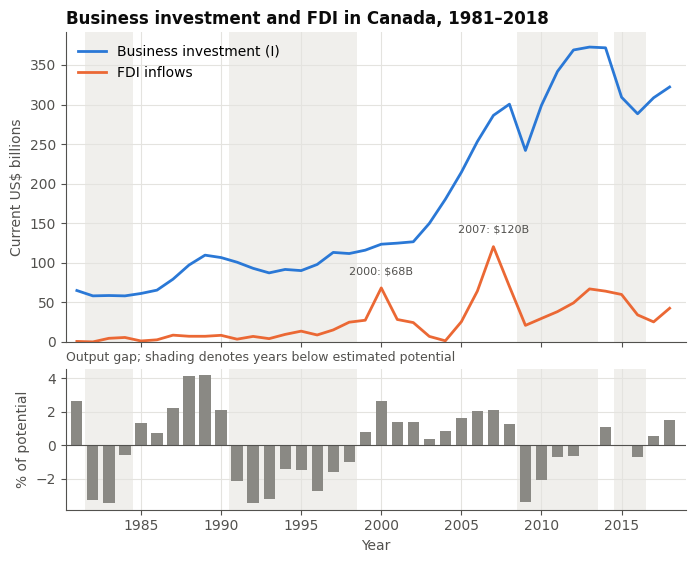

In [5]:
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8984"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False,
})

fig, (a1, a2) = plt.subplots(2, 1, figsize=(8, 6.2), sharex=True,
                             gridspec_kw={"height_ratios": [2.2, 1], "hspace": 0.12})
for ax in (a1, a2):                                   # shade years below potential
    for yr in base.index[base["gap_pct"] < 0]:
        ax.axvspan(yr - 0.5, yr + 0.5, color="#f0efec", lw=0, zorder=0)

a1.plot(base.index, base["I_usd"], color=BLUE, lw=2, label="Business investment (I)")
a1.plot(base.index, base["FDI_usd"], color=ORANGE, lw=2, label="FDI inflows")
for yr in (2000, 2007):
    a1.annotate(f"{yr}: ${base.loc[yr, 'FDI_usd']:.0f}B", xy=(yr, base.loc[yr, "FDI_usd"]),
                xytext=(0, 10), textcoords="offset points", ha="center", fontsize=8, color=INK2)
a1.set_ylabel("Current US$ billions"); a1.set_ylim(0, None); a1.legend(loc="upper left")
a1.set_title("Business investment and FDI in Canada, 1981–2018", loc="left", fontsize=12, fontweight="bold")

a2.bar(base.index, base["gap_pct"], color=GRAY, width=0.7)
a2.axhline(0, color=INK2, lw=0.8)
a2.set_ylabel("% of potential"); a2.set_xlabel("Year"); a2.set_xlim(1980.3, 2019.0)
a2.set_title("Output gap; shading denotes years below estimated potential", loc="left", fontsize=9, color=INK2)

fig.savefig(f"{FIG_DIR}/figure1_data.png", dpi=300, bbox_inches="tight")
plt.show()

## 4. Unit-root tests (Table 1)

Augmented Dickey–Fuller: levels with constant and trend, first differences with constant; lag length by AIC.

In [6]:
fmt_p = lambda p: "<0.001" if p < 0.001 else f"{p:.3f}"
rows = []
for v in ["I", "Y", "U", "FDI"]:
    lvl = adfuller(usd[v].dropna(), regression="ct", autolag="AIC")
    dif = adfuller(usd[v].diff().dropna(), regression="c", autolag="AIC")
    rows.append({"Variable": v, "ADF stat (level)": f"{lvl[0]:.2f}", "p (level)": fmt_p(lvl[1]),
                 "ADF stat (diff.)": f"{dif[0]:.2f}", "p (diff.)": fmt_p(dif[1])})
table1 = pd.DataFrame(rows).set_index("Variable")
table1

,ADF stat (level),p (level),ADF stat (diff.),p (diff.)
Variable,,,,
I,-2.99,0.136,-4.59,<0.001
Y,-3.33,0.061,-4.15,<0.001
U,-3.60,0.029,-5.41,<0.001
FDI,-4.99,<0.001,-5.25,<0.001


## 5. Levels models: OLS and AR(1)

The original specification, I = α + βY + γU + δFDI + ε, first by OLS and then with AR(1) errors (iterative GLSAR).

In [7]:
ols = smf.ols("I ~ Y + U + FDI", data=usd).fit()
print(ols.summary())
print("Durbin-Watson:", round(durbin_watson(ols.resid), 3))

                            OLS Regression Results                            
Dep. Variable:                      I   R-squared:                       0.994
Model:                            OLS   Adj. R-squared:                  0.993
Method:                 Least Squares   F-statistic:                     1849.
Date:                Sun, 01 Nov 2026   Prob (F-statistic):           1.04e-37
Time:                        02:18:51   Log-Likelihood:                -134.37
No. Observations:                  38   AIC:                             276.7
Df Residuals:                      34   BIC:                             283.3
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -11.9798      2.952     -4.058      0.0

In [8]:
ar1 = GLSAR.from_formula("I ~ Y + U + FDI", data=usd, rho=1).iterative_fit(maxiter=50)
print(ar1.summary())
print("rho:", np.round(ar1.model.rho, 3), "| Durbin-Watson:", round(durbin_watson(ar1.wresid), 3))

                           GLSAR Regression Results                           
Dep. Variable:                      I   R-squared:                       0.983
Model:                          GLSAR   Adj. R-squared:                  0.981
Method:                 Least Squares   F-statistic:                     631.3
Date:                Sun, 01 Nov 2026   Prob (F-statistic):           3.33e-29
Time:                        02:18:53   Log-Likelihood:                -115.20
No. Observations:                  37   AIC:                             238.4
Df Residuals:                      33   BIC:                             244.9
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -16.7569      5.784     -2.897      0.0

## 6. Cointegration and the error-correction model (Table 2)

Engle–Granger test of the I–Y long-run relationship, then the short-run ECM:
ΔI = κ + θΔY + γU + δFDI + λECT₋₁ + e, with Newey–West (HAC, 3 lags) standard errors.

In [9]:
eg_stat, eg_p, _ = coint(usd["I"], usd["Y"], trend="c")
print(f"Engle-Granger (I, Y): stat = {eg_stat:.2f}, p = {eg_p:.3f}")

ecm = smf.ols("dI ~ dY + U + FDI + ECT", data=usd).fit(**HAC)
print(ecm.summary())

Engle-Granger (I, Y): stat = -4.33, p = 0.002
                            OLS Regression Results                            
Dep. Variable:                     dI   R-squared:                       0.923
Model:                            OLS   Adj. R-squared:                  0.914
Method:                 Least Squares   F-statistic:                     294.8
Date:                Sun, 01 Nov 2026   Prob (F-statistic):           9.34e-25
Time:                        02:18:56   Log-Likelihood:                -120.53
No. Observations:                  37   AIC:                             251.1
Df Residuals:                      32   BIC:                             259.1
Df Model:                           4                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Interc

In [10]:
table2 = summary_col([ols, ar1, ecm], stars=True, float_format="%.3f",
                     model_names=["OLS levels", "AR(1) levels", "ECM (HAC)"],
                     regressor_order=["Y", "dY", "U", "FDI", "ECT", "Intercept"],
                     info_dict={"N": lambda m: f"{int(m.nobs)}"}).tables[0]
table2 = table2.replace("", " ")
table2.index = [{"dY": "ΔY"}.get(i, i) for i in table2.index]
table2

,OLS levels,AR(1) levels,ECM (HAC)
Y,0.194***,0.198***,
,(0.004),(0.005),
ΔY,,,0.224***
,,,(0.010)
U,-0.281***,-0.342***,-0.174*
,(0.096),(0.078),(0.099)
FDI,0.124,0.053,0.027
,(0.085),(0.063),(0.054)
ECT,,,-0.369**
,,,(0.158)


## 7. Residual diagnostics

Breusch–Godfrey test (2 lags) on the main ECM. Two dynamic variants are shown for reference: adding lagged ΔI
(note: a lagged dependent variable with autocorrelated errors biases OLS) and adding lagged ΔY.

In [11]:
ecm_plain = smf.ols("dI ~ dY + U + FDI + ECT", data=usd).fit()
print(f"Breusch-Godfrey p, main ECM: {acorr_breusch_godfrey(ecm_plain, nlags=2)[1]:.3f}")

usd["dI_lag"], usd["dY_lag"] = usd["dI"].shift(1), usd["dY"].shift(1)
for label, formula in [("+ lagged dI", "dI ~ dY + U + FDI + ECT + dI_lag"),
                       ("+ lagged dY", "dI ~ dY + dY_lag + U + FDI + ECT")]:
    m = smf.ols(formula, data=usd).fit()
    print(f"Breusch-Godfrey p, ECM {label}: {acorr_breusch_godfrey(m, nlags=2)[1]:.3f}  "
          f"| FDI = {m.params['FDI']:.3f}")

Breusch-Godfrey p, main ECM: 0.001
Breusch-Godfrey p, ECM + lagged dI: 0.001  | FDI = 0.020
Breusch-Godfrey p, ECM + lagged dY: 0.000  | FDI = 0.027


## 8. Specification sensitivity (Table 3)

The CAD and extended USD samples do not reject no cointegration at 5%. Their ECMs are exploratory comparisons, not equally supported error-correction models. CAD change equations omit ECT but retain U and FDI in levels. The separate audit tests these retained series and checks model dynamics; see docs/REVISION_NOTES.md.


In [12]:
models = {
    "ECM, US$ (main)":              (usd,     smf.ols("dI ~ dY + U + FDI + ECT", data=usd).fit(**HAC)),
    "ECM + FDI x U":                (usd,     smf.ols("dI ~ dY + U + FDI + FDI:U + ECT", data=usd).fit(**HAC)),
    "ECM, C$":                      (cad,     smf.ols("dI ~ dY + U + FDI + ECT", data=cad).fit(**HAC)),
    "ECM, US$ to 2024 + 2020":      (usd_ext, smf.ols("dI ~ dY + U + FDI + ECT + covid", data=usd_ext).fit(**HAC)),
    "First differences, C$":        (cad,     smf.ols("dI ~ dY + U + FDI", data=cad).fit(**HAC)),
    "First diff., C$ + exch. rate": (cad,     smf.ols("dI ~ dY + U + FDI + fx", data=cad).fit(**HAC)),
}
rows = []
for name, (d, m) in models.items():
    row = {"Specification": name, "N": int(m.nobs),
           "Coint. p": f"{coint(d['I'], d['Y'], trend='c')[1]:.3f}",
           "FDI coef.": f"{m.params['FDI']:.3f}", "FDI p": fmt_p(m.pvalues["FDI"])}
    row["FDI x U"] = f"{m.params['FDI:U']:.3f} (p={m.pvalues['FDI:U']:.3f})" if "FDI:U" in m.params else "-"
    rows.append(row)
table3 = pd.DataFrame(rows).set_index("Specification")
table3

,N,Coint. p,FDI coef.,FDI p,FDI x U
Specification,,,,,
"ECM, US$ (main)",37,0.002,0.027,0.615,-
ECM + FDI x U,37,0.002,0.071,0.356,0.003 (p=0.267)
"ECM, C$",37,0.382,-0.071,0.009,-
"ECM, US$ to 2024 + 2020",43,0.358,0.032,0.548,-
"First differences, C$",37,0.382,-0.107,<0.001,-
"First diff., C$ + exch. rate",37,0.382,-0.108,<0.001,-


## 9. Figure 2: the FDI coefficient across specifications

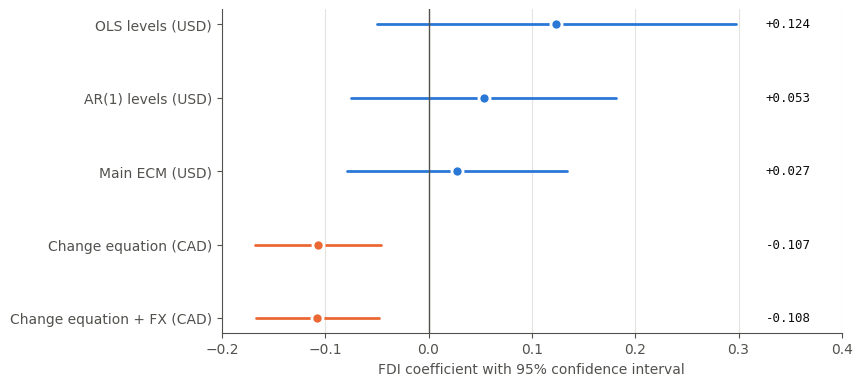

,spec,currency,coef,lo,hi,p,N
0,OLS levels (USD),US$,0.124,-0.050,0.297,0.156,38
1,AR(1) levels (USD),US$,0.053,-0.075,0.182,0.405,37
2,Main ECM (USD),US$,0.027,-0.079,0.134,0.615,37
3,Change equation (CAD),C$,-0.107,-0.168,-0.046,0.001,37
4,Change equation + FX (CAD),C$,-0.108,-0.167,-0.048,0.000,37


In [13]:
fig2_specs = [("OLS levels (USD)", "US$", ols), ("AR(1) levels (USD)", "US$", ar1),
              ("Main ECM (USD)", "US$", ecm),
              ("Change equation (CAD)", "C$", models["First differences, C$"][1]),
              ("Change equation + FX (CAD)", "C$", models["First diff., C$ + exch. rate"][1])]
coefs = pd.DataFrame([{"spec": s, "currency": c, "coef": m.params["FDI"],
                       "lo": m.conf_int().loc["FDI"][0], "hi": m.conf_int().loc["FDI"][1],
                       "p": m.pvalues["FDI"], "N": int(m.nobs)} for s, c, m in fig2_specs])

fig, ax = plt.subplots(figsize=(8, 4.2))
ypos = np.arange(len(coefs))[::-1]
for y, r in zip(ypos, coefs.itertuples()):
    c = BLUE if r.currency == "US$" else ORANGE
    ax.plot([r.lo, r.hi], [y, y], color=c, lw=2, solid_capstyle="round")
    ax.plot(r.coef, y, "o", ms=8, color=c, mec="white", mew=2, zorder=3)
    ax.text(0.37, y, f"{r.coef:+.3f}", va="center", ha="right", fontsize=9, color=INK, family="DejaVu Sans Mono")
ax.axvline(0, color=INK2, lw=1)
ax.set_yticks(ypos, coefs["spec"]); ax.set_xlim(-0.2, 0.4); ax.grid(axis="y", visible=False)
ax.set_xlabel("FDI coefficient with 95% confidence interval")
fig.savefig(f"{FIG_DIR}/figure2_fdi_coefficients.png", dpi=300, bbox_inches="tight")
plt.show()
coefs.round(3)

## 10. Export tables

In [14]:
table1.to_csv(f"{TAB_DIR}/table1_adf.csv")
table2.to_csv(f"{TAB_DIR}/table2_main_estimates.csv")
table3.to_csv(f"{TAB_DIR}/table3_robustness.csv")
coefs.to_csv(f"{TAB_DIR}/figure2_fdi_coefficients.csv", index=False)
print(sorted(os.listdir(TAB_DIR)), sorted(os.listdir(FIG_DIR)))

['figure2_fdi_coefficients.csv', 'table1_adf.csv', 'table2_main_estimates.csv', 'table3_robustness.csv'] ['figure1_data.png', 'figure2_fdi_coefficients.png']
